# Which Texas Bird Is It? · Notebook 1: Data and Preprocessing

**DATA 4380 · Alejandro Alfonso, Tej Govindu, Mateen Jan**

**Question:** Can a convolutional neural network (CNN) identify 10 common Texas bird species from a photo, including three pairs of lookalike birds?

This notebook covers:
1. Loading the images and checking their quality
2. Exploring the data (class counts, sample images, lookalike pairs)
3. Making our own train / validation / test split

The modeling is in notebook 2.

### Glossary (plain-English definitions)

| Term | Meaning |
|---|---|
| **Image classification** | Giving a whole image one label (here: which bird species it shows). |
| **Class** | One of the possible labels. We have 10 classes, one per species. |
| **Pixel / RGB** | An image is a grid of pixels; each pixel has a Red, Green and Blue value from 0 to 255. Our images are 224 × 224 pixels × 3 colors. |
| **Train / validation / test split** | *Train* images teach the model. *Validation* images are used to compare models and choose settings. *Test* images are kept aside and used only at the end to report final results. |
| **Stratified split** | A split that keeps the same share of each class in train, validation and test. |
| **Duplicate** | The exact same image file appearing more than once. Duplicates across splits would let the model "cheat" on the test set. |
| **Augmentation** | Making small random changes to training images (flip, rotate, zoom) so the model sees more variety. Covered in notebook 2. |
| **Lookalike pair** | Two species that look similar (e.g., two hawks). We expect most model mistakes here. |

In [1]:
import hashlib
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image
from sklearn.model_selection import train_test_split

RAW = Path("../data/raw")
OUT = Path("../data/processed")
FIG = Path("../reports/figures")
OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

SEED = 42
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. Data source

- **Dataset:** *BIRDS 525 Species – Image Classification* by Gerald Piosenka (originally on Kaggle). The Kaggle page has since been removed, so we downloaded the identical files from a public-domain (CC0) mirror on Hugging Face: `chriamue/bird-species-dataset`.
- The full dataset has 525 species and about 89,900 images. Every image is a 224 × 224 color JPG, cropped so one bird fills most of the frame.
- **We kept 10 species that live in Texas** (`src/download_data.sh` downloads only these):

| Group | Species |
|---|---|
| Distinctive | Northern Cardinal, Northern Mockingbird (Texas state bird), Roadrunner, Green Jay |
| Lookalike pair: doves | Mourning Dove, Rock Dove (city pigeon) |
| Lookalike pair: hawks | Red Tailed Hawk, Red Shouldered Hawk |
| Lookalike pair: black birds | Crow, Common Grackle |

The dataset had no Blue Jay, so we used the Green Jay, a jay found in South Texas.

## 2. Load every image path into a table

In [2]:
rows = []
for split_dir in ["train", "valid", "test"]:
    for species_dir in sorted((RAW / split_dir).iterdir()):
        for f in sorted(species_dir.glob("*.jpg")):
            rows.append({"path": f.as_posix(), "species": species_dir.name.title(), "original_split": split_dir})
df = pd.DataFrame(rows)
print(f"{len(df):,} images, {df.species.nunique()} species")
pd.crosstab(df.species, df.original_split)[["train", "valid", "test"]]

1,710 images, 10 species


original_split,train,valid,test
species,,,
Common Grackle,177,5,5
Crow,163,5,5
Green Jay,156,5,5
Mourning Dove,153,5,5
Northern Cardinal,155,5,5
Northern Mockingbird,140,5,5
Red Shouldered Hawk,172,5,5
Red Tailed Hawk,202,5,5
Roadrunner,160,5,5


**What this shows:** the original dataset gives only **5 test images per species** (50 total). One mistake would move test accuracy by 2 points, which is too noisy to judge a model. So we **pool all 1,710 images and make our own split** (section 6).

## 3. Quality checks: size, color mode, broken files, duplicates

In [3]:
def inspect(path):
    with open(path, "rb") as fh:
        raw = fh.read()
    try:
        with Image.open(path) as im:
            im.verify()
        with Image.open(path) as im:
            return pd.Series({"width": im.width, "height": im.height, "mode": im.mode, "ok": True,
                              "md5": hashlib.md5(raw).hexdigest()})
    except Exception:
        return pd.Series({"width": None, "height": None, "mode": None, "ok": False, "md5": hashlib.md5(raw).hexdigest()})

df = df.join(df.path.apply(inspect))
print("Broken files:", (~df.ok).sum())
print("Image sizes:", df.groupby(["width", "height"]).size().to_dict())
print("Color modes:", df["mode"].value_counts().to_dict())
dupes = df[df.duplicated("md5", keep=False)].sort_values("md5")
print("Images that are exact duplicates of another image:", len(dupes))
dupes[["species", "original_split", "path"]]

Broken files: 0
Image sizes: {(224, 224): 1710}
Color modes: {'RGB': 1710}
Images that are exact duplicates of another image: 0


,species,original_split,path


If any exact duplicates appear above, we keep only one copy of each, so the same photo can't land in both training and test.

In [4]:
before = len(df)
df = df.drop_duplicates("md5").reset_index(drop=True)
print(f"Removed {before - len(df)} duplicate(s); {len(df):,} images remain")

Removed 0 duplicate(s); 1,710 images remain


## 4. How many images per species?

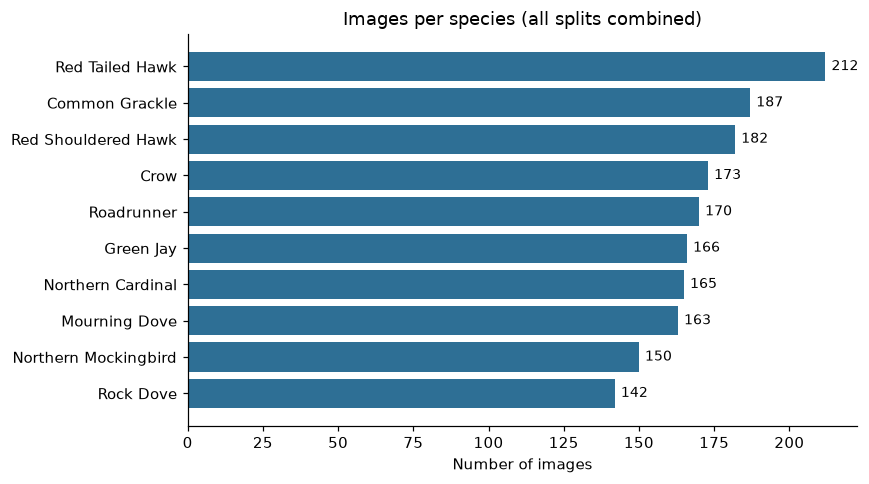

Smallest class: 142  Largest: 212  Ratio: 1.49


In [5]:
counts = df.species.value_counts().sort_values()
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(counts.index, counts.values, color="#2E6F95")
for i, v in enumerate(counts.values):
    ax.text(v + 2, i, str(v), va="center", fontsize=9)
ax.set_xlabel("Number of images")
ax.set_title("Images per species (all splits combined)")
plt.tight_layout()
plt.savefig(FIG / "class_counts.png", bbox_inches="tight")
plt.show()
print(f"Smallest class: {counts.min()}  Largest: {counts.max()}  Ratio: {counts.max() / counts.min():.2f}")

**What this shows:** every species has between about 140 and 210 images. The largest class is only about 1.5× the smallest, so the classes are **fairly balanced**. We don't need resampling (unlike the Dallas 311 project), but we'll still report per-class scores, not just overall accuracy.

## 5. What do the images look like?

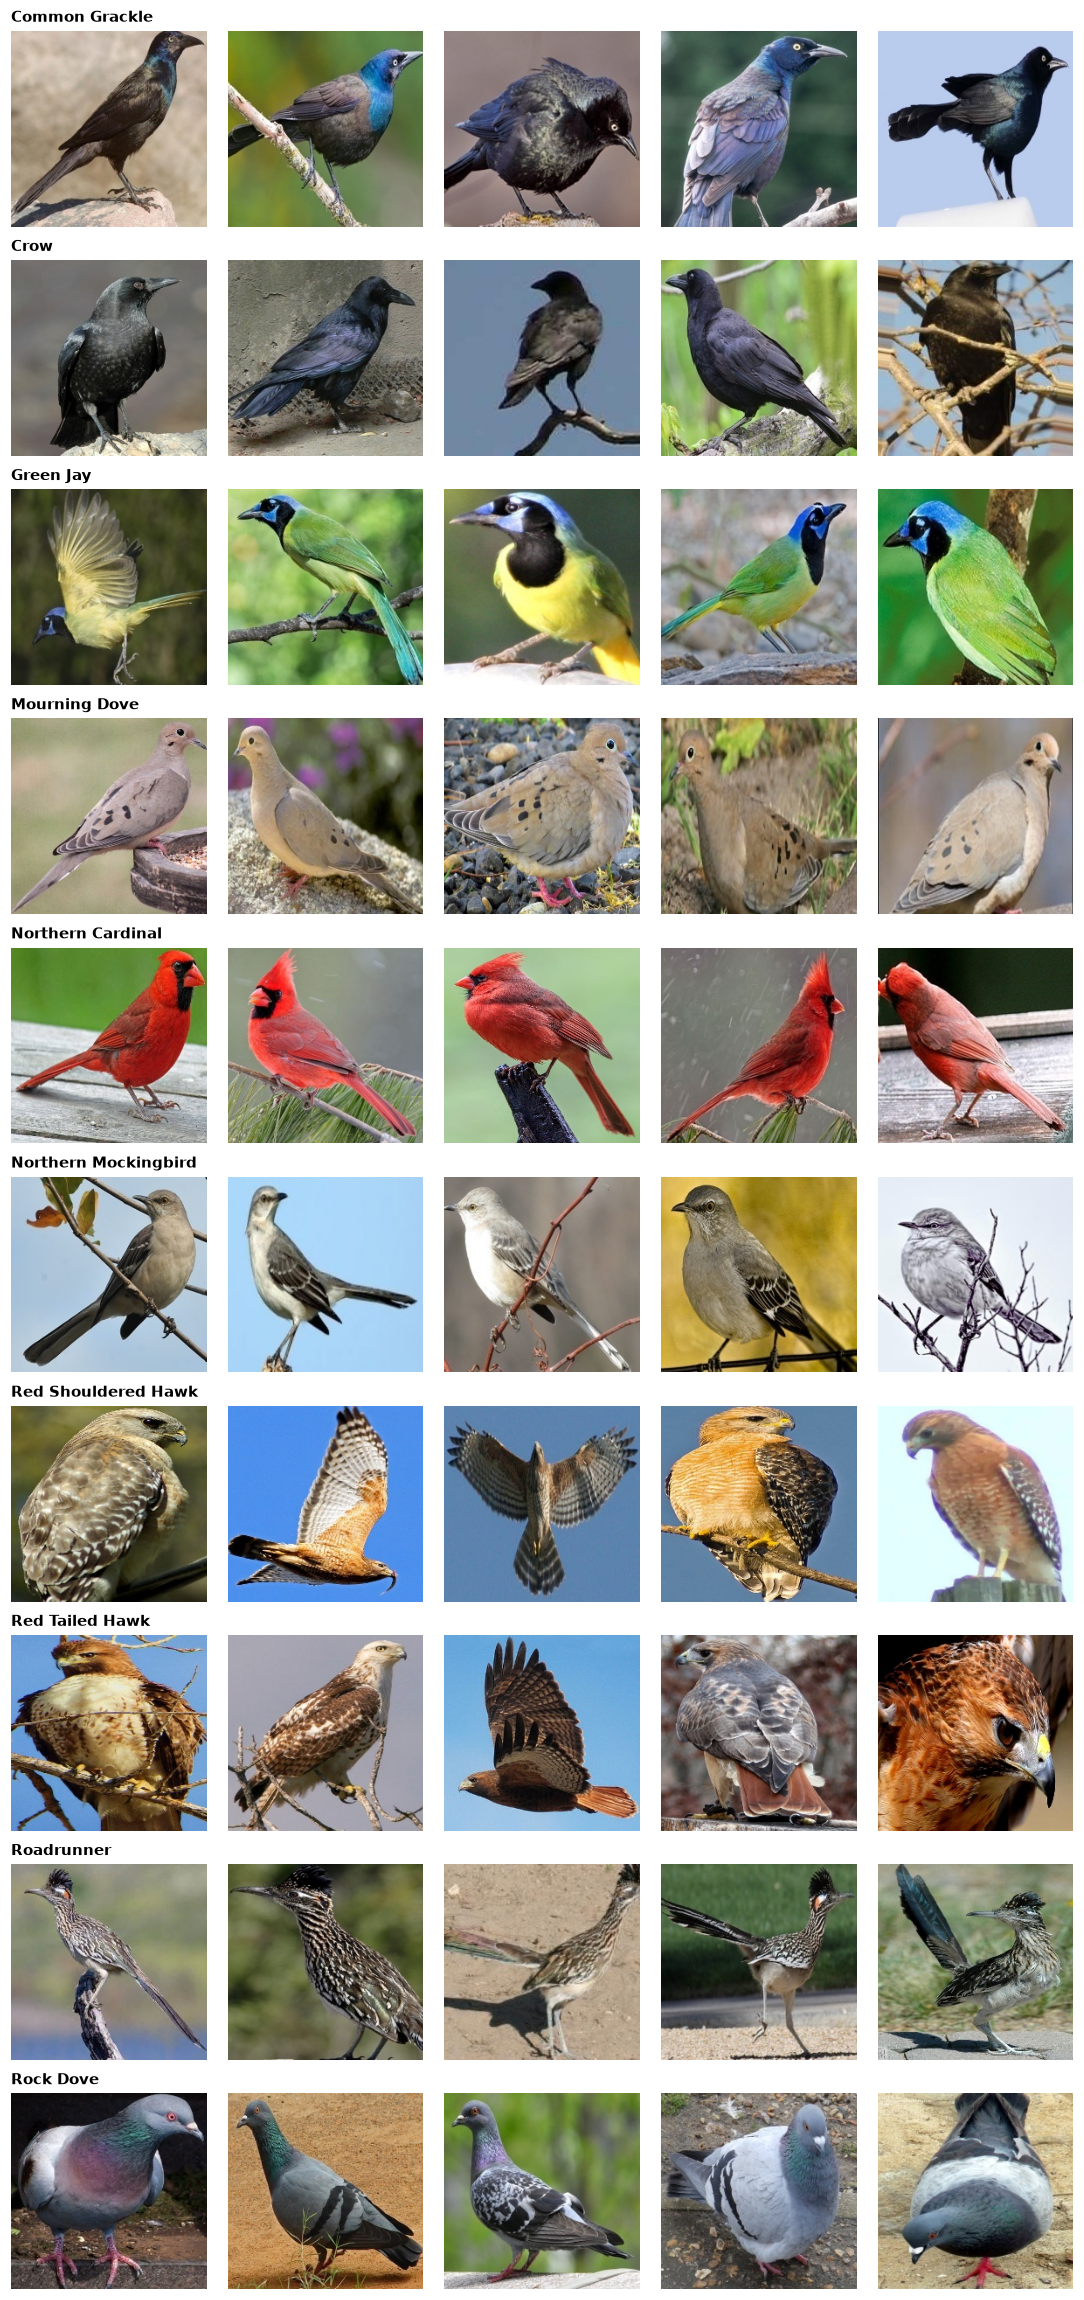

In [6]:
species = sorted(df.species.unique())
fig, axes = plt.subplots(len(species), 5, figsize=(10, 2.1 * len(species)))
for r, sp in enumerate(species):
    sample = df[df.species == sp].sample(5, random_state=SEED)
    for c, p in enumerate(sample.path):
        ax = axes[r, c]
        ax.imshow(Image.open(p))
        ax.axis("off")
    axes[r, 0].set_title(sp, loc="left", fontsize=10, fontweight="bold")
plt.tight_layout()
plt.savefig(FIG / "sample_grid.png", bbox_inches="tight")
plt.show()

**What this shows:** birds are centered and fill most of the frame, but backgrounds (sky, branches, grass, water) and poses vary a lot. Some images show the bird from behind or in flight. That variety is what makes this harder than it first looks.

### The three lookalike pairs side by side

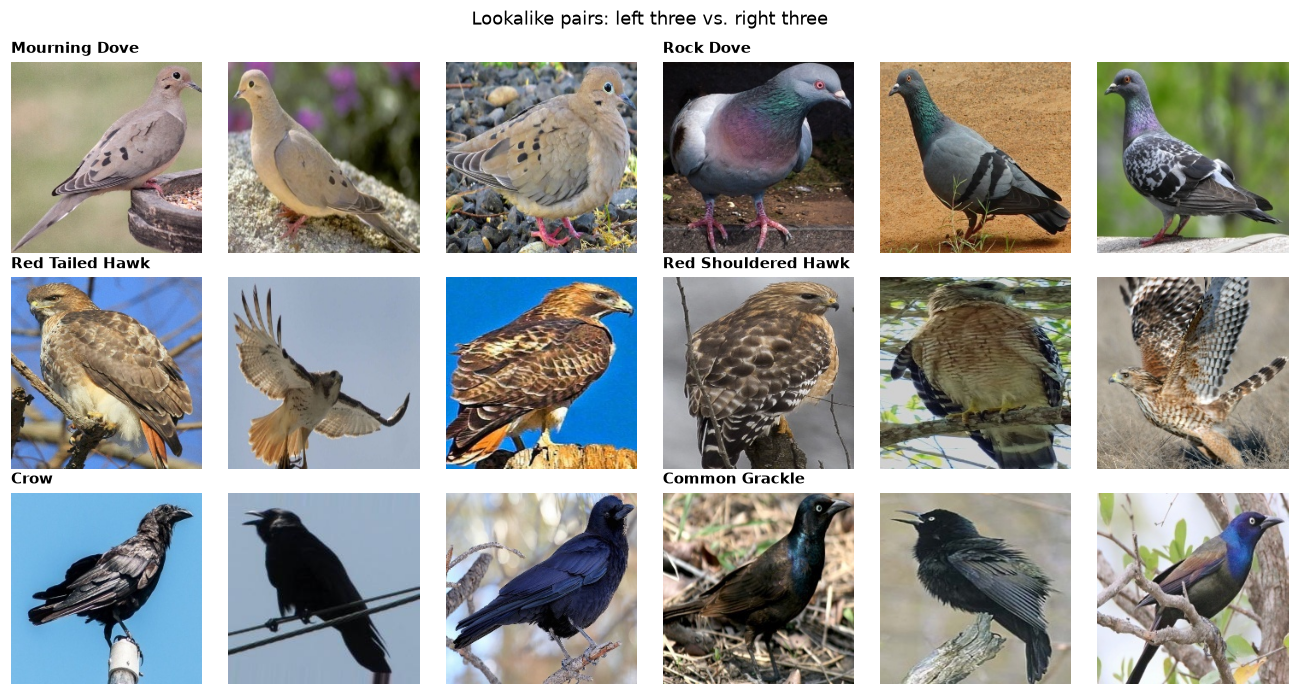

In [7]:
pairs = [("Mourning Dove", "Rock Dove"), ("Red Tailed Hawk", "Red Shouldered Hawk"), ("Crow", "Common Grackle")]
fig, axes = plt.subplots(3, 6, figsize=(12, 6.4))
for r, (a, b) in enumerate(pairs):
    for c in range(3):
        for k, sp in enumerate((a, b)):
            ax = axes[r, c + 3 * k]
            p = df[df.species == sp].sample(3, random_state=SEED + r).path.iloc[c]
            ax.imshow(Image.open(p))
            ax.axis("off")
            if c == 0:
                ax.set_title(sp, loc="left", fontsize=10, fontweight="bold")
plt.suptitle("Lookalike pairs: left three vs. right three", fontsize=12)
plt.tight_layout()
plt.savefig(FIG / "lookalike_pairs.png", bbox_inches="tight")
plt.show()

**What this shows:** a person can tell these apart (a grackle has yellow eyes and a long tail; a red-shouldered hawk has a barred orange chest), but the differences are small details. **Our expectation:** most of the model's mistakes will be inside these pairs. We'll check that with the confusion matrix in notebook 2.

## 6. Our own stratified 70 / 15 / 15 split

In [8]:
train, temp = train_test_split(df, test_size=0.30, stratify=df.species, random_state=SEED)
val, test = train_test_split(temp, test_size=0.50, stratify=temp.species, random_state=SEED)
df["split"] = "train"
df.loc[val.index, "split"] = "val"
df.loc[test.index, "split"] = "test"

table = pd.crosstab(df.species, df.split)[["train", "val", "test"]]
table.loc["TOTAL"] = table.sum()
table

split,train,val,test
species,,,
Common Grackle,131,28,28
Crow,121,26,26
Green Jay,116,25,25
Mourning Dove,114,24,25
Northern Cardinal,116,24,25
Northern Mockingbird,105,23,22
Red Shouldered Hawk,128,27,27
Red Tailed Hawk,148,32,32
Roadrunner,119,25,26


In [9]:
# No image (by file hash) should appear in more than one split
assert df.groupby("md5").split.nunique().max() == 1
df[["path", "species", "split"]].to_csv(OUT / "splits.csv", index=False)
print("Saved", OUT / "splits.csv")

Saved ..\data\processed\splits.csv


**Why this split:**
- **Stratified:** each species keeps the same share in train, validation and test, so no species is under-represented in the test set.
- **70 / 15 / 15:** about 1,200 images to learn from and about 255 each for validation and test, giving roughly 25 test images per species instead of 5.
- **Fixed random seed (42):** anyone who reruns the notebook gets the exact same split.
- **Test set:** used only once, at the end of notebook 2.

## 7. Preprocessing plan for notebook 2

| Step | What we do | Why |
|---|---|---|
| Resize | Already 224 × 224, so no resizing needed | Matches the input size of pretrained models like MobileNetV2 |
| Scale pixels | 0–255 → the range the model expects | Neural networks train better on small, consistent numbers |
| Augmentation (train only) | Random horizontal flip, small rotation (±10%), zoom (±10%), contrast change | Only about 120 training images per bird; augmentation adds variety so the model doesn't memorize backgrounds |
| No augmentation on val/test | Images used as-is | We want to measure performance on real, unchanged photos |

## Summary
- 1,710 images, 10 species, all 224 × 224 RGB, with no broken files.
- The classes are fairly balanced (about 140–210 images each).
- We replaced the original 5-per-class test set with our own stratified 70/15/15 split, saved in `data/processed/splits.csv`.
- **Expectation going into modeling:** distinctive birds (cardinal, roadrunner, green jay) will be easy; the three lookalike pairs will cause most errors.